# Medical Insurance Cost Prediction
**End-to-end machine learning workflow: EDA → feature engineering → modelling → tuning → interpretation**

Dataset: [Kaggle – Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance) (1,338 records; features: age, sex, BMI, children, smoker, region; target: `charges`).

**Objective:** predict individual annual medical insurance charges and identify the key cost drivers.

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.compose import TransformedTargetRegressor
try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

## 2. Load the data
Tries the Kaggle dataset via `kagglehub` first and falls back to a public GitHub mirror of the same file, so the notebook runs in Colab without a Kaggle API key.

In [2]:
def load_data():
    try:
        import kagglehub
        path = kagglehub.dataset_download("mirichoi0218/insurance")
        return pd.read_csv(f"{path}/insurance.csv")
    except Exception as e:
        print("kagglehub unavailable, using GitHub mirror:", type(e).__name__)
        url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
        return pd.read_csv(url)

df = load_data()
print(df.shape)
df.head()

kagglehub unavailable, using GitHub mirror: ModuleNotFoundError
(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 3. Data quality checks

In [3]:
print("Missing values:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after de-duplication:", df.shape, "\n")
display(df.describe().T.round(2))
display(df.describe(include="object").T)

Missing values:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64 

Duplicate rows: 1
Shape after de-duplication: (1337, 7) 



,count,mean,std,min,25%,50%,75%,max
age,1337.0,39.22,14.04,18.00,27.00,39.00,51.00,64.00
bmi,1337.0,30.66,6.10,15.96,26.29,30.40,34.70,53.13
children,1337.0,1.10,1.21,0.00,0.00,1.00,2.00,5.00
charges,1337.0,13279.12,12110.36,1121.87,4746.34,9386.16,16657.72,63770.43


,count,unique,top,freq
sex,1337,2,male,675
smoker,1337,2,no,1063
region,1337,4,southeast,364


## 4. Exploratory data analysis

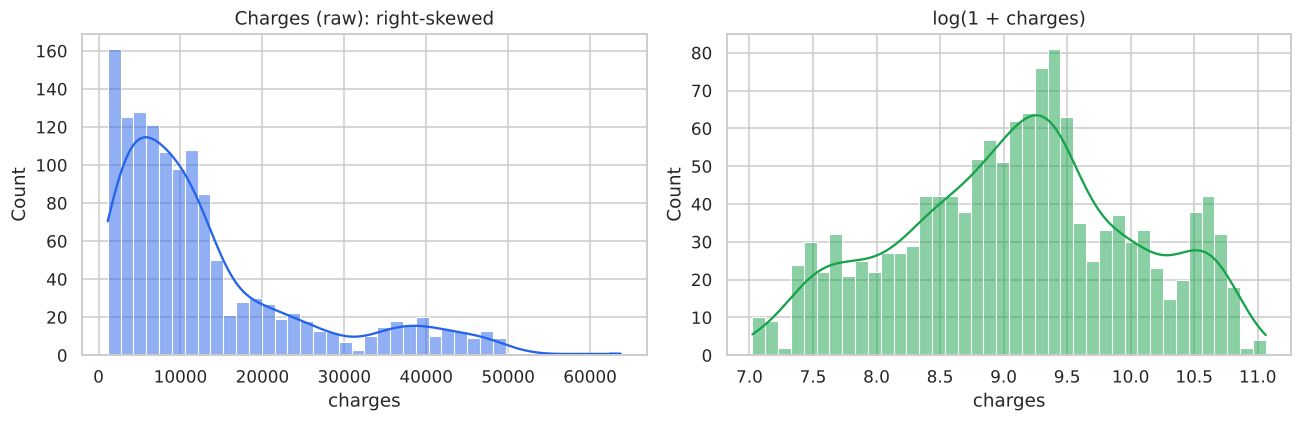

Skewness raw: 1.52 | log: -0.09


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df.charges, bins=40, kde=True, ax=ax[0], color="#2563eb"); ax[0].set_title("Charges (raw): right-skewed")
sns.histplot(np.log1p(df.charges), bins=40, kde=True, ax=ax[1], color="#16a34a"); ax[1].set_title("log(1 + charges)")
plt.tight_layout(); plt.show()
print("Skewness raw:", round(df.charges.skew(), 2), "| log:", round(np.log1p(df.charges).skew(), 2))

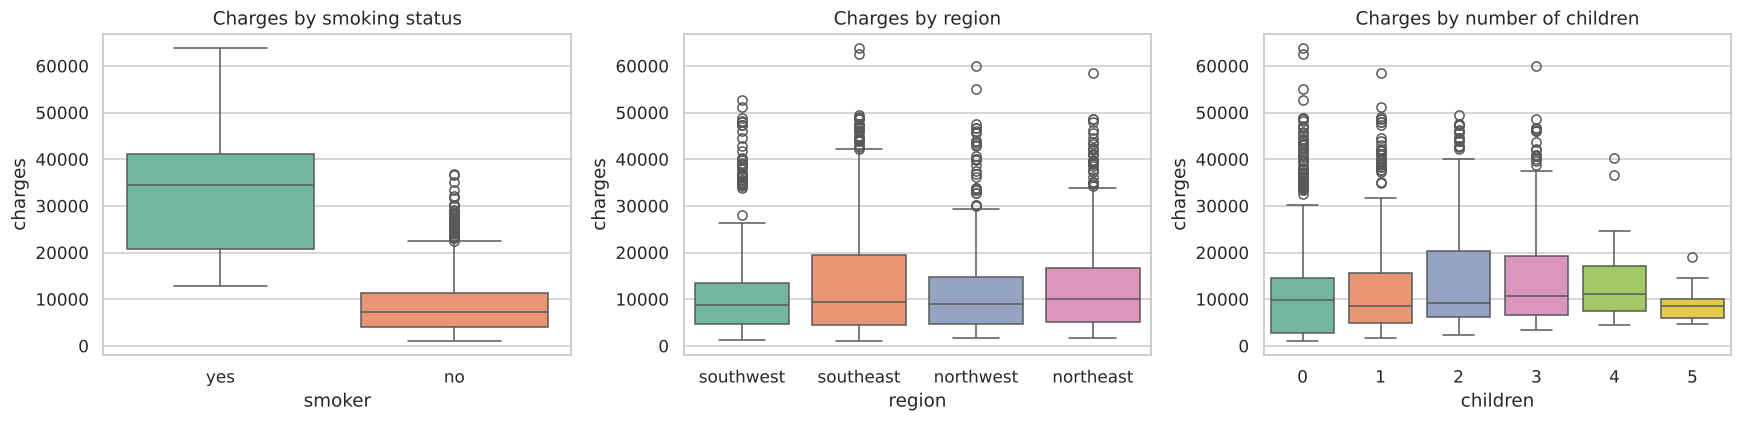

        count     mean   median
smoker                         
no       1063   8441.0   7346.0
yes       274  32050.0  34456.0


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=df, x="smoker", y="charges", ax=ax[0], palette="Set2"); ax[0].set_title("Charges by smoking status")
sns.boxplot(data=df, x="region", y="charges", ax=ax[1], palette="Set2"); ax[1].set_title("Charges by region")
sns.boxplot(data=df, x="children", y="charges", ax=ax[2], palette="Set2"); ax[2].set_title("Charges by number of children")
plt.tight_layout(); plt.show()
print(df.groupby("smoker").charges.agg(["count", "mean", "median"]).round(0))

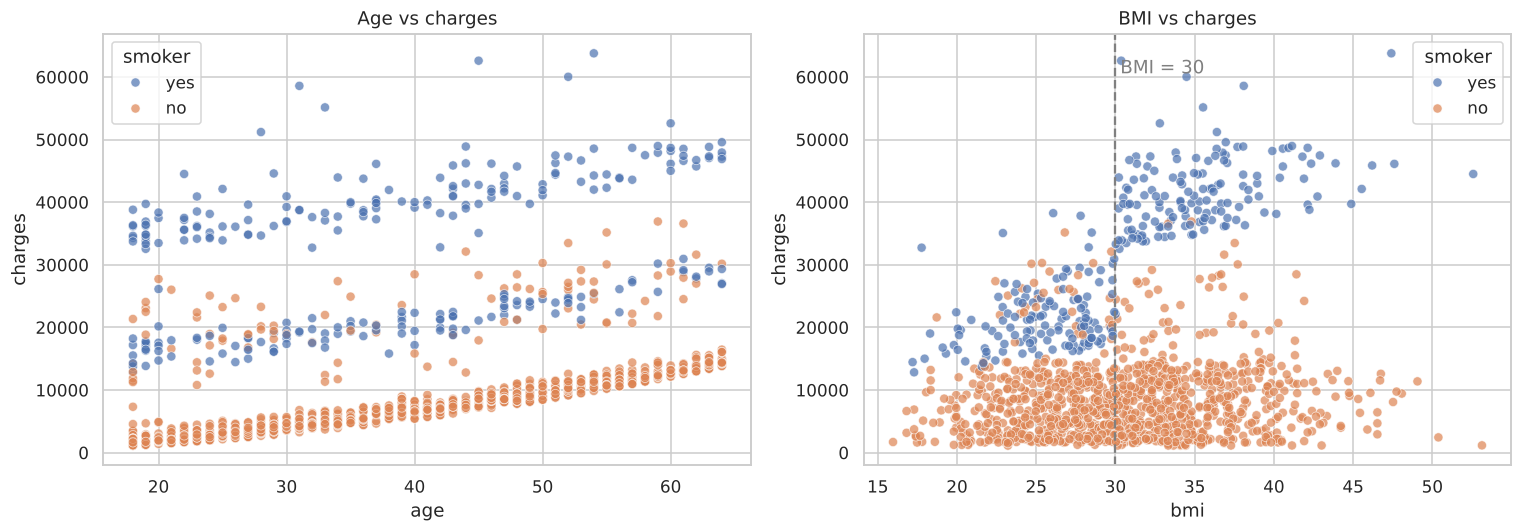

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=.7, ax=ax[0]); ax[0].set_title("Age vs charges")
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=.7, ax=ax[1]); ax[1].set_title("BMI vs charges")
ax[1].axvline(30, ls="--", c="grey"); ax[1].text(30.3, df.charges.max()*.95, "BMI = 30", color="grey")
plt.tight_layout(); plt.show()

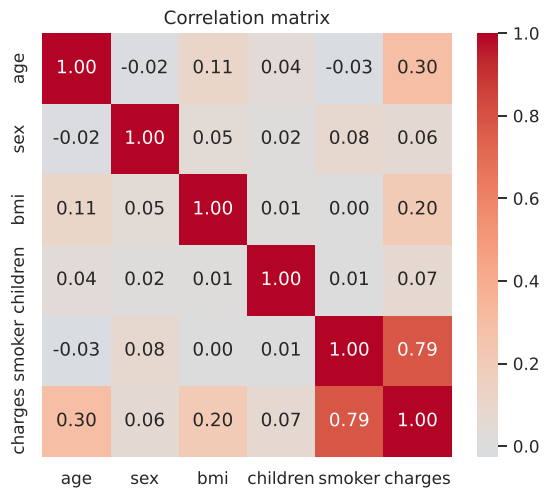

In [7]:
num = df.assign(smoker=(df.smoker == "yes").astype(int), sex=(df.sex == "male").astype(int)).select_dtypes("number")
plt.figure(figsize=(6, 5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

**EDA takeaways**
- Charges are strongly right-skewed → modelling log-charges stabilises variance.
- Smoking is by far the strongest driver; smokers form a distinct, much costlier cluster.
- Charges rise with age in three visible bands; BMI above ~30 matters mainly **for smokers** (an interaction effect).
- Sex, region and children show weak marginal effects.

### 4.1 Statistical hypothesis tests
EDA impressions are confirmed with formal tests (significance level α = 0.05).

In [8]:
from scipy import stats
sm, ns = df[df.smoker == "yes"].charges, df[df.smoker == "no"].charges
t, p = stats.ttest_ind(sm, ns, equal_var=False)
u, pu = stats.mannwhitneyu(sm, ns)
pooled = np.sqrt((sm.var() + ns.var()) / 2); d = (sm.mean() - ns.mean()) / pooled
print(f"Smoker vs non-smoker  | Welch t = {t:.1f}, p = {p:.2e} | Mann-Whitney p = {pu:.2e} | Cohen's d = {d:.2f}")
f, pf = stats.f_oneway(*[g.charges.values for _, g in df.groupby("region")])
print(f"Region (one-way ANOVA)| F = {f:.2f}, p = {pf:.3f}")
sx_m, sx_f = df[df.sex == "male"].charges, df[df.sex == "female"].charges
t2, p2 = stats.ttest_ind(sx_m, sx_f, equal_var=False)
print(f"Sex (Welch t-test)    | t = {t2:.2f}, p = {p2:.3f}")
for c in ["age", "bmi", "children"]:
    r, pr = stats.spearmanr(df[c], df.charges)
    print(f"Spearman {c:<9}      | rho = {r:.2f}, p = {pr:.2e}")

Smoker vs non-smoker  | Welch t = 32.7, p = 6.26e-103 | Mann-Whitney p = 5.75e-130 | Cohen's d = 2.57
Region (one-way ANOVA)| F = 2.93, p = 0.033
Sex (Welch t-test)    | t = 2.13, p = 0.034
Spearman age            | rho = 0.53, p = 3.19e-99
Spearman bmi            | rho = 0.12, p = 1.16e-05
Spearman children       | rho = 0.13, p = 1.23e-06


## 5. Feature engineering

In [9]:
def add_features(d):
    d = d.copy()
    d["obese"] = (d.bmi >= 30).astype(int)
    d["smoker_obese"] = ((d.smoker == "yes") & (d.bmi >= 30)).astype(int)
    d["smoker_bmi"] = (d.smoker == "yes").astype(int) * d.bmi
    d["age_sq"] = d.age ** 2
    return d

data = add_features(df)
X, y = data.drop(columns="charges"), data.charges
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=X.smoker)
print(X_train.shape, X_test.shape)

(1069, 10) (268, 10)


## 6. Preprocessing pipeline & model comparison
All models are wrapped in a single `Pipeline` (no leakage) and trained on **log-charges** via `TransformedTargetRegressor`; metrics are always reported in original dollars. Evaluation uses 5-fold CV on the training set.

In [10]:
cat_cols = ["sex", "smoker", "region"]
num_cols = [c for c in X.columns if c not in cat_cols]

def make_pre(scale=True):
    return ColumnTransformer([
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
        ("num", StandardScaler() if scale else "passthrough", num_cols)])

def wrap(model, scale=True):
    return TransformedTargetRegressor(
        regressor=Pipeline([("pre", make_pre(scale)), ("model", model)]),
        func=np.log1p, inverse_func=np.expm1)

models = {
    "Linear Regression": wrap(LinearRegression()),
    "Ridge": wrap(Ridge(alpha=1.0)),
    "Random Forest": wrap(RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1), scale=False),
    "Gradient Boosting": wrap(GradientBoostingRegressor(random_state=SEED), scale=False),
}
if HAS_XGB:
    models["XGBoost"] = wrap(XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=.8,
                                          colsample_bytree=.8, random_state=SEED), scale=False)

cv = KFold(5, shuffle=True, random_state=SEED)
scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}
rows = []
for name, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": name, "CV R²": s["test_r2"].mean(), "CV R² std": s["test_r2"].std(),
                 "CV MAE ($)": -s["test_mae"].mean(), "CV RMSE ($)": -s["test_rmse"].mean()})
cv_results = pd.DataFrame(rows).set_index("Model").sort_values("CV R²", ascending=False)
cv_results.round(3)

,CV R²,CV R² std,CV MAE ($),CV RMSE ($)
Model,,,,
Random Forest,0.836,0.042,2329.949,4809.281
XGBoost,0.831,0.040,2415.764,4885.933
Gradient Boosting,0.830,0.046,2413.559,4886.013
Linear Regression,0.502,0.055,4289.639,8491.249
Ridge,0.495,0.063,4285.289,8549.948


## 7. Hyperparameter tuning (Gradient Boosting)

In [11]:
grid = {
    "regressor__model__n_estimators": [100, 200, 300],
    "regressor__model__learning_rate": [0.03, 0.05, 0.1],
    "regressor__model__max_depth": [2, 3, 4],
    "regressor__model__min_samples_leaf": [5, 10],
}
gs = GridSearchCV(models["Gradient Boosting"], grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
gs.fit(X_train, y_train)
print("Best params:", {k.split("__")[-1]: v for k, v in gs.best_params_.items()})
print("Best CV RMSE: $%.0f" % -gs.best_score_)
best = gs.best_estimator_

Best params: {'learning_rate': 0.05, 'max_depth': 4, 'min_samples_leaf': 10, 'n_estimators': 100}
Best CV RMSE: $4759


## 8. Final evaluation on the hold-out test set

In [12]:
def report(name, model):
    p = model.predict(X_test)
    return {"Model": name, "R²": r2_score(y_test, p), "MAE ($)": mean_absolute_error(y_test, p),
            "RMSE ($)": np.sqrt(mean_squared_error(y_test, p))}

final = pd.DataFrame([report(n, m.fit(X_train, y_train)) for n, m in models.items()] + [report("Tuned Gradient Boosting", best)])
final = final.set_index("Model").sort_values("R²", ascending=False)
display(final.round(3))

,R²,MAE ($),RMSE ($)
Model,,,
Tuned Gradient Boosting,0.926,1569.651,3266.122
Random Forest,0.920,1706.795,3394.757
Gradient Boosting,0.917,1713.408,3453.418
XGBoost,0.917,1722.297,3458.076
Ridge,0.549,3697.137,8058.970
Linear Regression,0.547,3731.768,8085.398


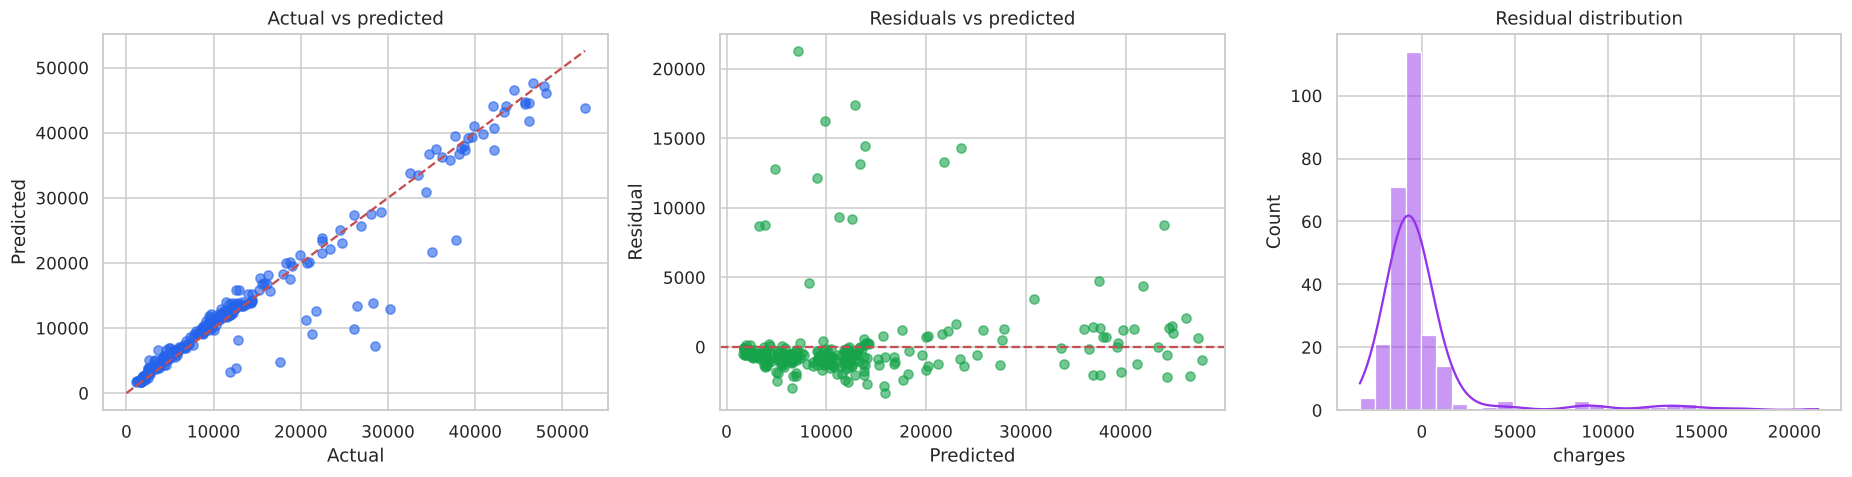

Error by segment (MAE / median AE, $):


,mean,median
smoker,,
no,1489.0,788.0
yes,1881.0,1236.0


In [13]:
pred = best.predict(X_test); resid = y_test - pred
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(y_test, pred, alpha=.6, c="#2563eb"); lim = [0, max(y_test.max(), pred.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set(xlabel="Actual", ylabel="Predicted", title="Actual vs predicted")
ax[1].scatter(pred, resid, alpha=.6, c="#16a34a"); ax[1].axhline(0, c="r", ls="--"); ax[1].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs predicted")
sns.histplot(resid, bins=30, kde=True, ax=ax[2], color="#9333ea"); ax[2].set_title("Residual distribution")
plt.tight_layout(); plt.show()

seg = pd.DataFrame({"smoker": X_test.smoker, "abs_err": np.abs(resid)}).groupby("smoker").abs_err.agg(["mean", "median"]).round(0)
print("Error by segment (MAE / median AE, $):"); display(seg)

### 8.1 Uncertainty: bootstrap confidence intervals on the test set

In [14]:
rng = np.random.default_rng(SEED)
yt, pp = y_test.values, best.predict(X_test)
r2s, maes = [], []
for _ in range(2000):
    idx = rng.integers(0, len(yt), len(yt))
    r2s.append(r2_score(yt[idx], pp[idx])); maes.append(mean_absolute_error(yt[idx], pp[idx]))
ci = lambda a: np.percentile(a, [2.5, 97.5])
print("R²  95%% CI: %.3f - %.3f" % tuple(ci(r2s)))
print("MAE 95%% CI: $%.0f - $%.0f" % tuple(ci(maes)))

R²  95% CI: 0.879 - 0.960
MAE 95% CI: $1250 - $1930


## 9. Interpretability: permutation importance

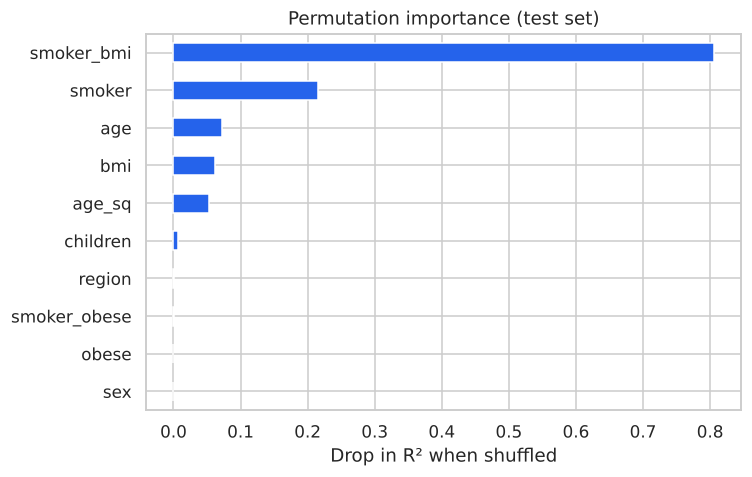

smoker_bmi      0.8063
smoker          0.2158
age             0.0724
bmi             0.0626
age_sq          0.0536
children        0.0068
region          0.0009
smoker_obese    0.0000
obese           0.0000
sex            -0.0004
dtype: float64

In [15]:
pi = permutation_importance(best, X_test, y_test, n_repeats=20, random_state=SEED, scoring="r2", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
imp.plot.barh(figsize=(7, 4.5), color="#2563eb"); plt.xlabel("Drop in R² when shuffled"); plt.title("Permutation importance (test set)")
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(4)

## 10. Save the model & predict for a new customer

In [16]:
import joblib
joblib.dump(best, "insurance_cost_model.joblib")

def predict_cost(age, sex, bmi, children, smoker, region):
    row = add_features(pd.DataFrame([dict(age=age, sex=sex, bmi=bmi, children=children, smoker=smoker, region=region)]))
    return float(best.predict(row)[0])

print("35y non-smoker, BMI 25 : $%.0f" % predict_cost(35, "female", 25, 1, "no", "northwest"))
print("35y smoker,     BMI 25 : $%.0f" % predict_cost(35, "female", 25, 1, "yes", "northwest"))
print("35y smoker,     BMI 35 : $%.0f" % predict_cost(35, "female", 35, 1, "yes", "northwest"))

35y non-smoker, BMI 25 : $6340
35y smoker,     BMI 25 : $19660
35y smoker,     BMI 35 : $39905


## 11. Conclusions & limitations
- **Smoking status, age and BMI** explain nearly all predictable variance; the smoker × BMI interaction is critical for linear models and captured automatically by tree ensembles.
- Tuned gradient boosting gives the best accuracy; errors are largest for high-cost smokers.
- **Limitations:** 1,338 records, one year, no clinical history or claims data; the dataset is synthetic-style and US-centric, so results should not be used for real underwriting decisions without validation on production data. Using `smoker` and `sex` in pricing may also raise regulatory and fairness concerns.
- **Next steps:** quantile/prediction-interval models, SHAP explanations, fairness audit, calibration by segment.